Implement time series forecasting for the NIFTY-50 dataset. Design and train a model to predict the future value sof the NIFTY-50 stockemarket index based on historical data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import MinMaxScaler

# Load and clean the NIFTY-50 data.
data = pd.read_csv("NIFTY.csv")
data.columns = data.columns.str.strip()
data["Date"] = pd.to_datetime(data["Date"], dayfirst=True)
data = data.sort_values("Date").set_index("Date")

features = ["Open", "High", "Low", "Close"]
split_index = int(len(data) * 0.8)
train_data = data.iloc[:split_index].copy()
test_data = data.iloc[split_index:].copy()

# Fit the scaler on training data only to avoid leaking test-set information.
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train_data[features])
test_scaled = scaler.transform(test_data[features])

model = tf.keras.Sequential([
    tf.keras.Input(shape=(len(features),)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1)
])
model.compile(loss="mse", optimizer="adam")

history = model.fit(
    train_scaled,
    train_scaled[:, features.index("Close")],
    epochs=70,
    validation_data=(
        test_scaled,
        test_scaled[:, features.index("Close")]
    ),
    verbose=0
)

# Convert scaled predictions back to NIFTY closing-price units.
predicted_scaled = model.predict(test_scaled, verbose=0).ravel()
close_index = features.index("Close")
predicted_close = (
    predicted_scaled * scaler.data_range_[close_index]
    + scaler.data_min_[close_index]
)
actual_close = test_data["Close"].to_numpy()
mae = mean_absolute_error(actual_close, predicted_close)

results = pd.DataFrame({
    "Date": test_data.index,
    "Actual Close": actual_close,
    "Predicted Close": predicted_close
})

print(f"Test MAE: {mae:.2f}")


I0000 00:00:1792567902.237251   13624 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792567902.380354   13624 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1792567904.036738   13624 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


/tmp/ipykernel_13624/3809614432.py:10: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data["Date"] = pd.to_datetime(data["Date"], dayfirst=True)
E0000 00:00:1792567905.203411   13624 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Test MAE: 9.12


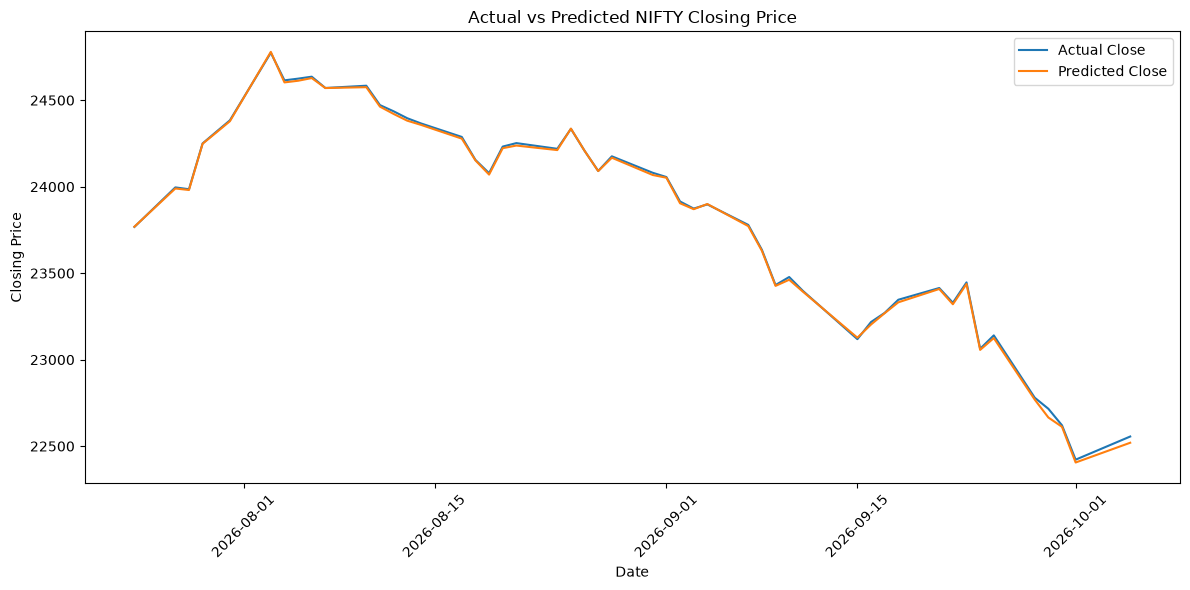

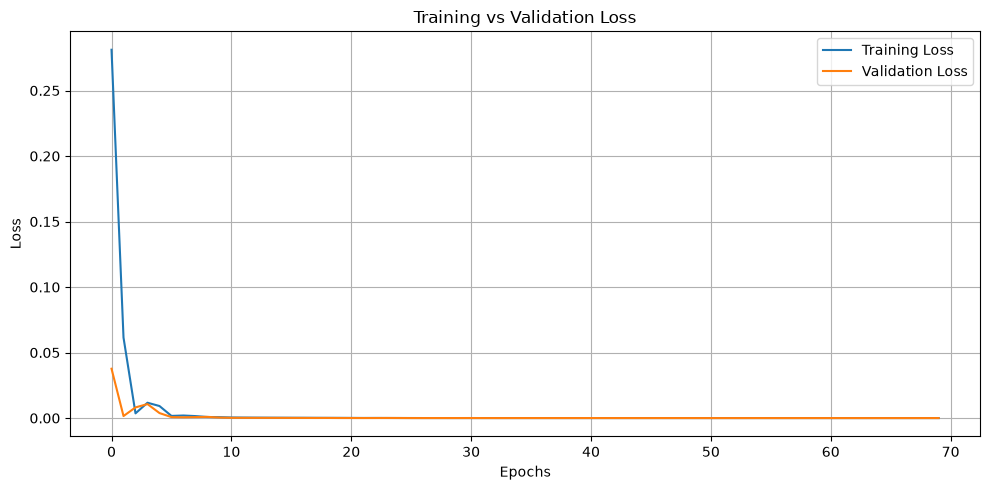

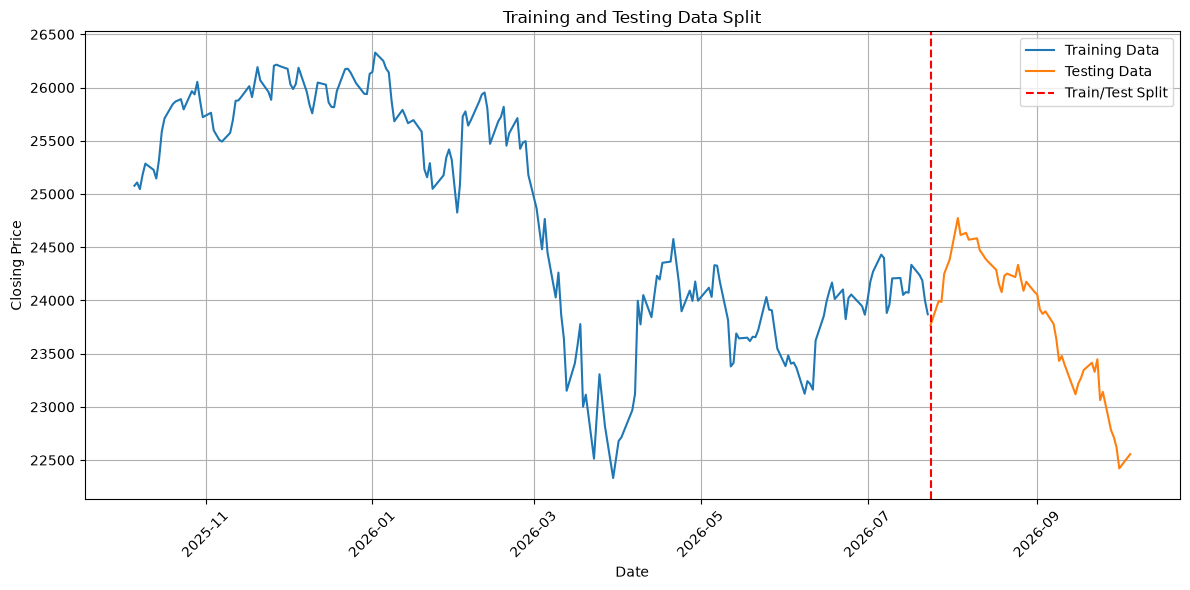

In [2]:
plt.figure(figsize=(12, 6))
plt.plot(results["Date"], results["Actual Close"], label="Actual Close")
plt.plot(results["Date"], results["Predicted Close"], label="Predicted Close")
plt.title("Actual vs Predicted NIFTY Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
plt.plot(train_data.index, train_data["Close"], label="Training Data")
plt.plot(test_data.index, test_data["Close"], label="Testing Data")
split_date = test_data.index[0]
plt.axvline(split_date, color="red", linestyle="--", label="Train/Test Split")
plt.title("Training and Testing Data Split")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()
